<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week15/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS15 - Pipeline Machine Learning & Deployment**<hr>
# **Tugas**
## **Deployment Model Project PBL: GlucoSafe (Klasifikasi Risiko Diabetes)**<hr>
*Pipeline: Training ANN -> Ekspor TFLite -> Deployment Flask (Render.com)*
<hr>

## **Langkah 1 - Import Library dan Mount Google Drive**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import json
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Langkah 2 - Load Dataset**


In [2]:
CSV_PATH = '/content/drive/MyDrive/pbl-ml/diabetes_binary_5050split_health_indicators_BRFSS2015.csv'
LABEL = 'Diabetes_binary'

df_raw = pd.read_csv(CSV_PATH)
print("Ukuran data awal:", df_raw.shape)
df_raw.head()

Ukuran data awal: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,0,1,26,0,0,0,1,0,...,1,0,3,5,30,0,1,4,6,8
1,0,1,1,1,26,1,1,0,0,1,...,1,0,3,0,0,0,1,12,6,8
2,0,0,0,1,26,0,0,0,1,1,...,1,0,1,0,10,0,1,13,6,8
3,0,1,1,1,28,1,0,0,1,1,...,1,0,3,0,3,0,1,11,6,8
4,0,0,0,1,29,1,0,0,1,1,...,1,0,2,0,0,0,0,8,5,8


## **Langkah 3 - Preprocessing Data**


In [3]:
# Fitur yang dibuang berdasarkan eksperimen sebelumnya
FITUR_DIBUANG = ['Income', 'CholCheck', 'HvyAlcoholConsump',
                 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.copy()

# 1. Buang fitur
df = df.drop(columns=FITUR_DIBUANG)

# 2. Hapus duplikat
df = df.drop_duplicates().reset_index(drop=True)

# 3. Tipe data (semua int kecuali BMI), label jadi int
df = df.astype({c: "int64" for c in df.columns if c != "BMI"})
df["BMI"] = df["BMI"].astype(float)

# 4. Pisah fitur dan label
X = df.drop(columns=[LABEL])
y = df[LABEL]
print(f"Ukuran data setelah dibersihkan: {df.shape}")
print(f"Fitur yang digunakan: {list(X.columns)}")

Ukuran data setelah dibersihkan: (63197, 16)
Fitur yang digunakan: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']


## **Langkah 4 - Split Data (Train & Test)**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (50557, 15) | Test: (12640, 15)


## **Langkah 5 - Penanganan Outlier dan Scaling**

In [5]:
# 1. Outlier BMI: clip pakai batas IQR dari train saja
q1, q3 = X_train["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
X_train["BMI"] = X_train["BMI"].clip(low, high)
X_test["BMI"] = X_test["BMI"].clip(low, high)

# 2. Scaling kolom numerik/ordinal (fit hanya di train)
num_cols = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Ubah ke array float32 untuk TensorFlow
X_tr = X_train_scaled.values.astype("float32")
X_te = X_test_scaled.values.astype("float32")
y_tr = y_train.values.astype("float32")
y_te = y_test.values.astype("float32")
print("Proses scaling selesai.")

Proses scaling selesai.


## **Langkah 6 - Membangun Arsitektur Model ANN**

In [6]:
tf.random.set_seed(42)
np.random.seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")   # Output biner (0/1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

## **Langkah 7 - Training Model ANN**

In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)
]

history = model.fit(
    X_tr, y_tr,
    validation_split=0.2,
    epochs=50,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7310 - auc: 0.8021 - loss: 0.5371 - val_accuracy: 0.7366 - val_auc: 0.8097 - val_loss: 0.5277 - learning_rate: 3.1250e-05
Epoch 2/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7313 - auc: 0.8021 - loss: 0.5375 - val_accuracy: 0.7367 - val_auc: 0.8096 - val_loss: 0.5279 - learning_rate: 3.1250e-05
Epoch 3/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7295 - auc: 0.8017 - loss: 0.5376 - val_accuracy: 0.7367 - val_auc: 0.8096 - val_loss: 0.5280 - learning_rate: 3.1250e-05
Epoch 4/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7316 - auc: 0.8028 - loss: 0.5369 - val_accuracy: 0.7370 - val_auc: 0.8096 - val_loss: 0.5281 - learning_rate: 3.1250e-05
Epoch 5/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7306 - auc: 0.8022 - loss: 0.5372 - val_accuracy: 0.7366 - val_auc: 0.8096 - val_loss: 0.5281 - learning_rate: 3.1250e-05
Epoch 6/50
1264/1264 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/s

## **Langkah 8 - Evaluasi Singkat Model**

In [10]:
test_loss, test_acc, test_auc = model.evaluate(X_te, y_te, verbose=0)
print(f"Akurasi Test : {test_acc:.4f}")
print(f"ROC-AUC Test : {test_auc:.4f}")

Akurasi Test : 0.7369
ROC-AUC Test : 0.8095


## **Langkah 9 - Ekspor Artefak Model (TFLite, Scaler, Features)**
*Model dikonversi ke TFLite agar ukurannya ringan (beberapa MB) dan tidak menyebabkan error Out of Memory (OOM) saat di-deploy di Render.com.*

In [11]:
# 1. Konversi Model Keras ke TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open('glucosafe_model.tflite', 'wb') as f:
    f.write(tflite_model)
print("✅ Model berhasil dikonversi ke: glucosafe_model.tflite")

# 2. Simpan Scaler
with open('glucosafe_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: glucosafe_scaler.pkl")

# 3. Simpan Daftar Urutan Fitur (PENTING untuk web)
with open('glucosafe_features.json', 'w') as f:
    json.dump(list(X_train.columns), f)
print("✅ Daftar fitur berhasil disimpan sebagai: glucosafe_features.json")

Saved artifact at '/tmp/tmpqt8vawa1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132690015457872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015459216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015458448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015458256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015458640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015455952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015459024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015459984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015459600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015459408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132690015457680: Tensor

## **Langkah 10 - Deployment (Render.com)**
*(Catatan: Karena Hugging Face Spaces sekarang mewajibkan akun PRO berbayar untuk Docker, deployment dialihkan ke Render.com menggunakan Flask dan Gunicorn).*

* **Link GitHub Repository:** https://github.com/Mufliha-Hafsyah/glucosafe-deploy.git <br>
* **Link Web Deployment:** https://glucosafe-app.onrender.com

**1. Struktur File Project di Laptop**
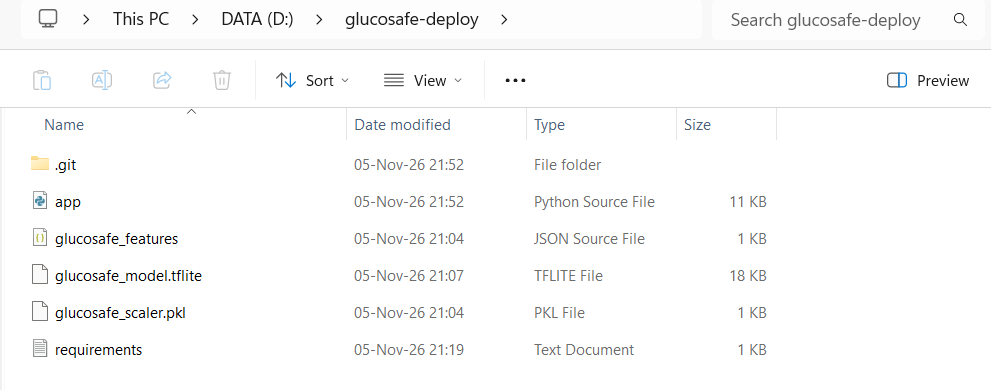

**2. Repository GitHub**
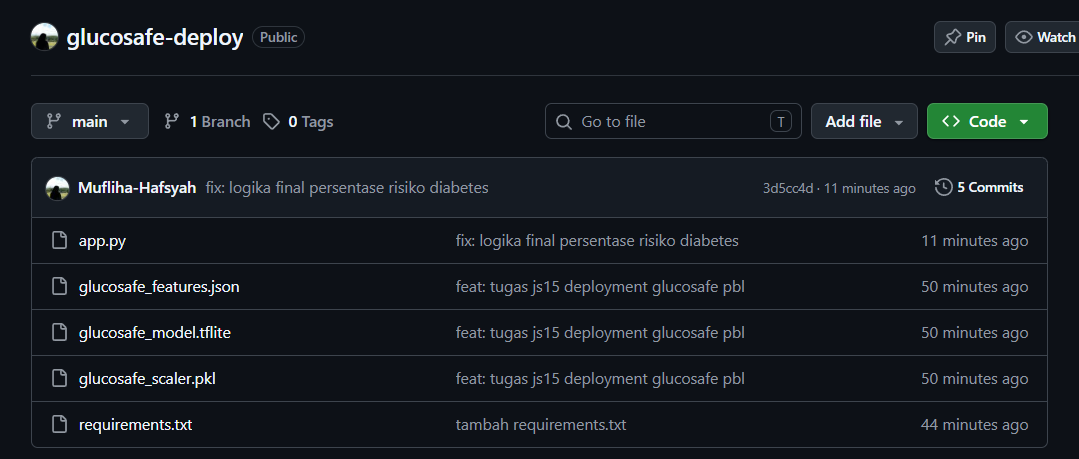

**3. Proses Build di Render.com**
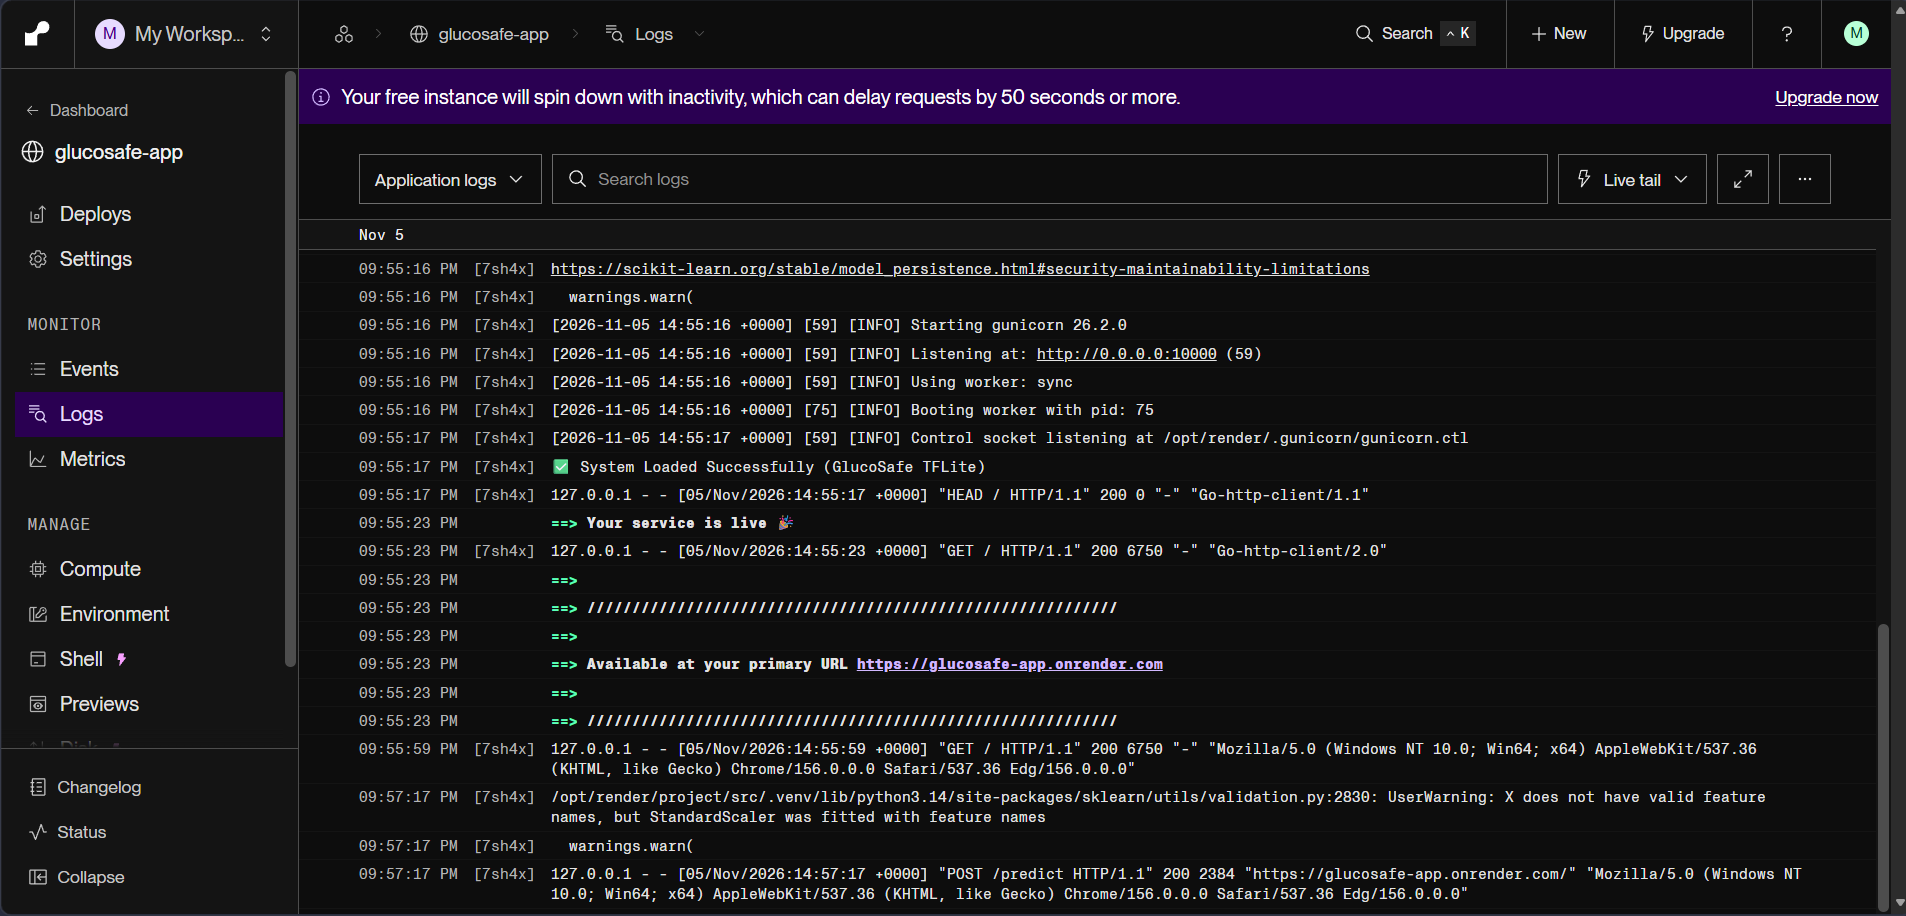

**4. Hasil Pengujian Web (Form & Hasil Prediksi)**
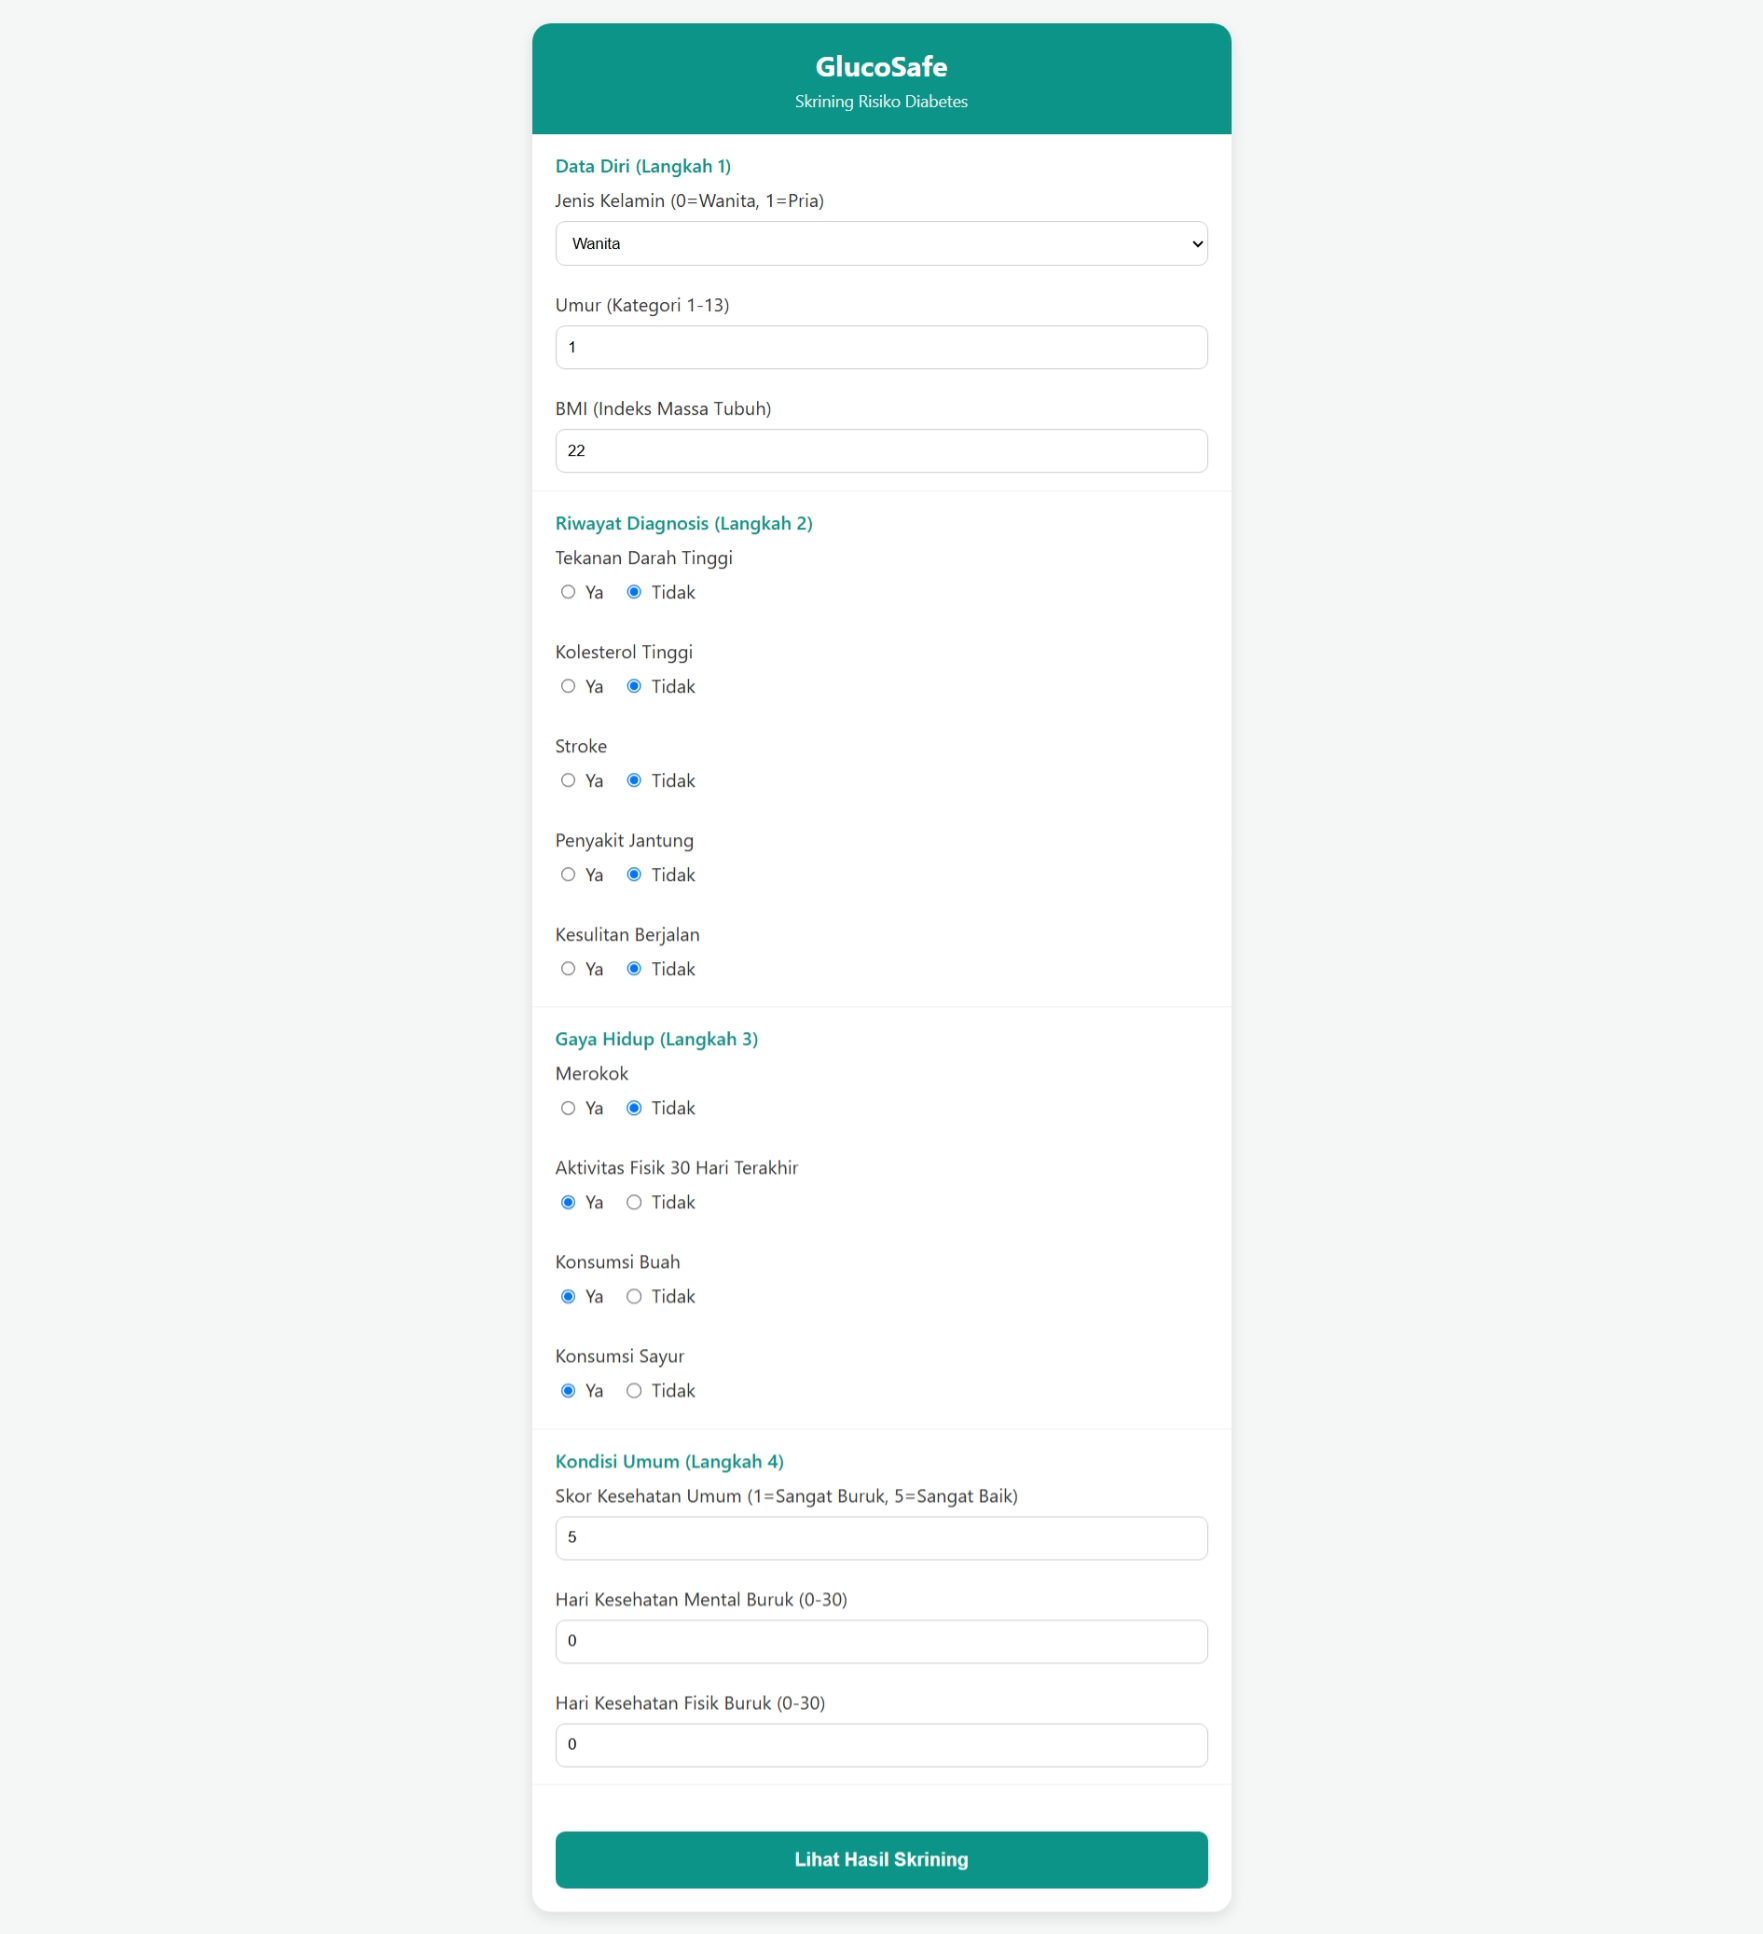
<br>
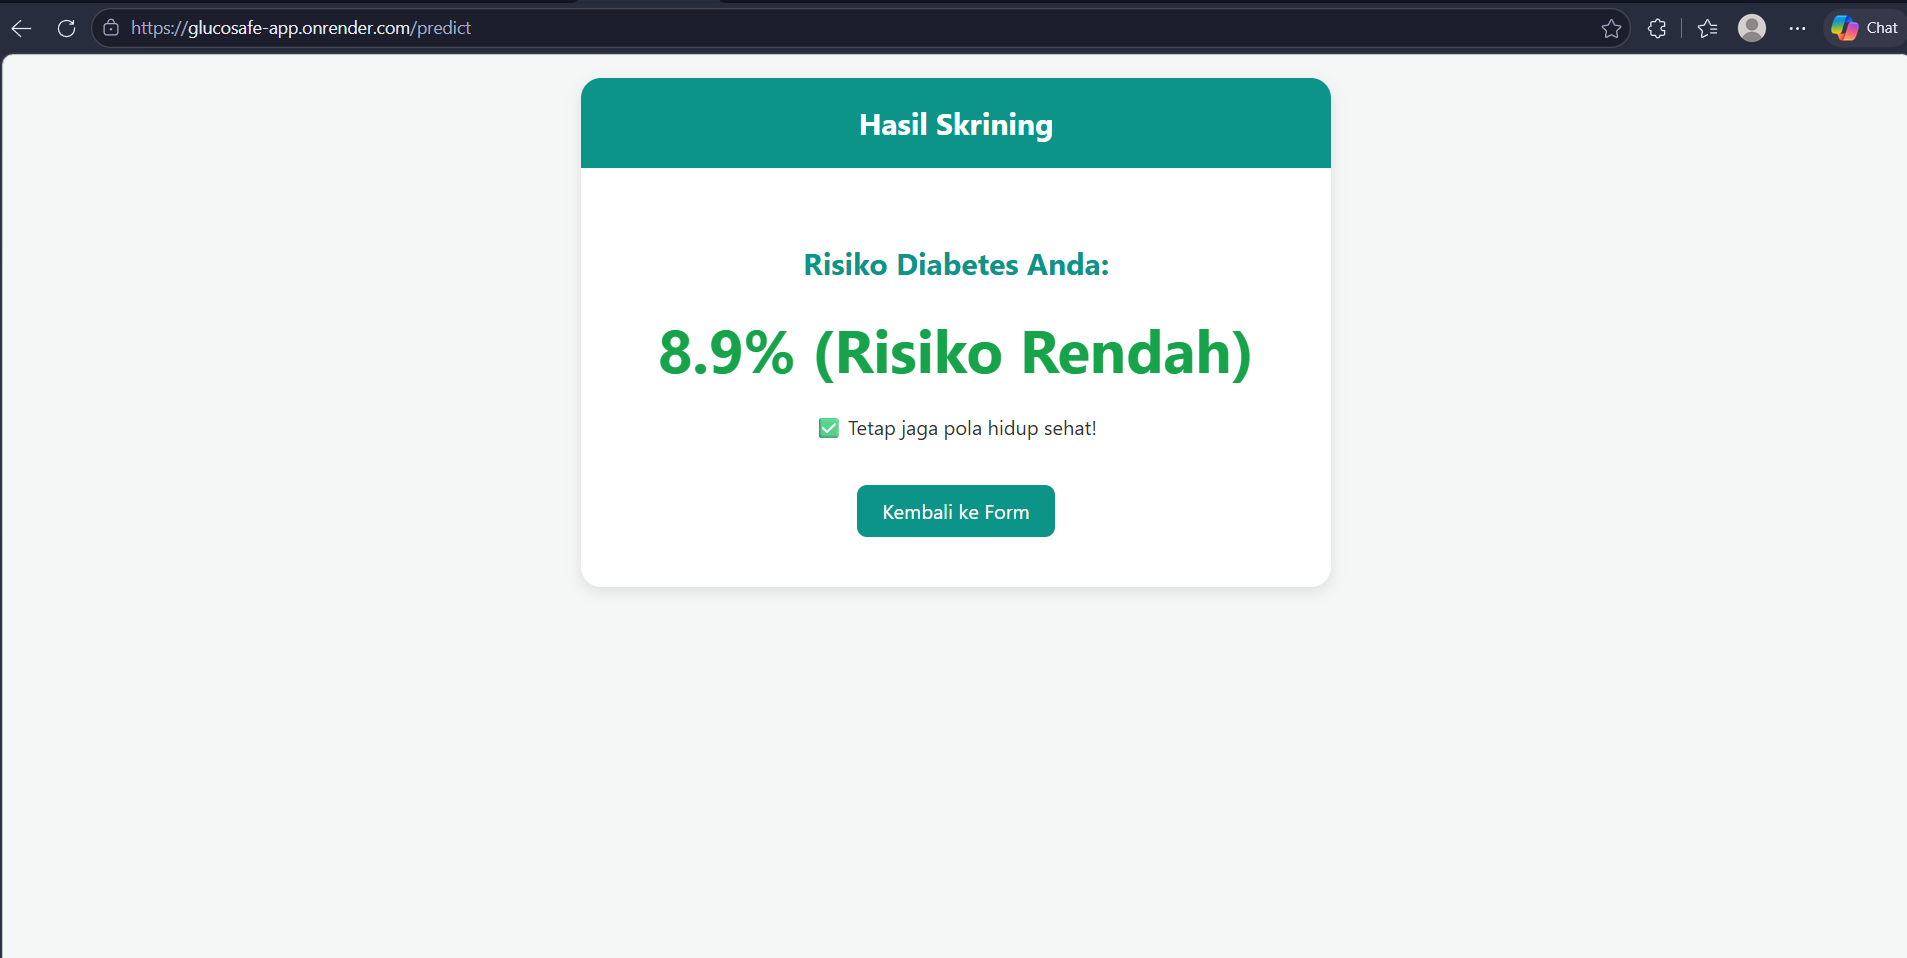